In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("TensorFlow:", tf.__version__)

# Paths and settings
dataset_path = Path("../dataset/chest_xray")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Dataset:", dataset_path.resolve())

TensorFlow: 2.21.0
Dataset: D:\Tanu H\TanushrisSPace\Projects\DL MINI PROJECT\dataset\chest_xray


In [2]:
# Load training, validation and test datasets

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "train",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "val",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "test",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [3]:
# Build Custom CNN

model = tf.keras.Sequential([
    # Normalize pixel values
    tf.keras.layers.Rescaling(1./255, input_shape=(224, 224, 3)),

    # Block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Block 3
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

d:\Tanu H\TanushrisSPace\Projects\DL MINI PROJECT\venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,561 (49.36 MB)

 Trainable params: 12,938,561 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Compile the Custom CNN

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("✅ Model compiled successfully!")

✅ Model compiled successfully!


In [5]:
# Data augmentation for training

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10)
], name="data_augmentation")

print("✅ Data augmentation created!")

✅ Data augmentation created!


In [6]:
# Custom CNN with data augmentation

model = tf.keras.Sequential([
    # Data augmentation
    data_augmentation,

    # Normalize pixel values
    tf.keras.layers.Rescaling(1./255),

    # Convolutional Block 1
    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the final baseline CNN

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("✅ Custom CNN is ready for training!")

✅ Custom CNN is ready for training!


In [8]:
# Callbacks to prevent unnecessary training and save the best model

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "../results/custom_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15


d:\Tanu H\TanushrisSPace\Projects\DL MINI PROJECT\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


163/163 ━━━━━━━━━━━━━━━━━━━━ 190s 1s/step - accuracy: 0.7981 - loss: 0.4434 - precision: 0.8100 - recall: 0.9515 - val_accuracy: 0.6250 - val_loss: 0.7056 - val_precision: 0.5714 - val_recall: 1.0000
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 181s 1s/step - accuracy: 0.8988 - loss: 0.2492 - precision: 0.9242 - recall: 0.9409 - val_accuracy: 0.8125 - val_loss: 0.5534 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - accuracy: 0.9229 - loss: 0.1970 - precision: 0.9447 - recall: 0.9520 - val_accuracy: 0.8750 - val_loss: 0.3054 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.9337 - loss: 0.1738 - precision: 0.9556 - recall: 0.9551 - val_accuracy: 0.9375 - val_loss: 0.2816 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.9375 - loss: 0.1691 - precision: 0.9565 - recall: 0.9595 - val_accuracy: 0.7500 - val_loss: 0.4034 -

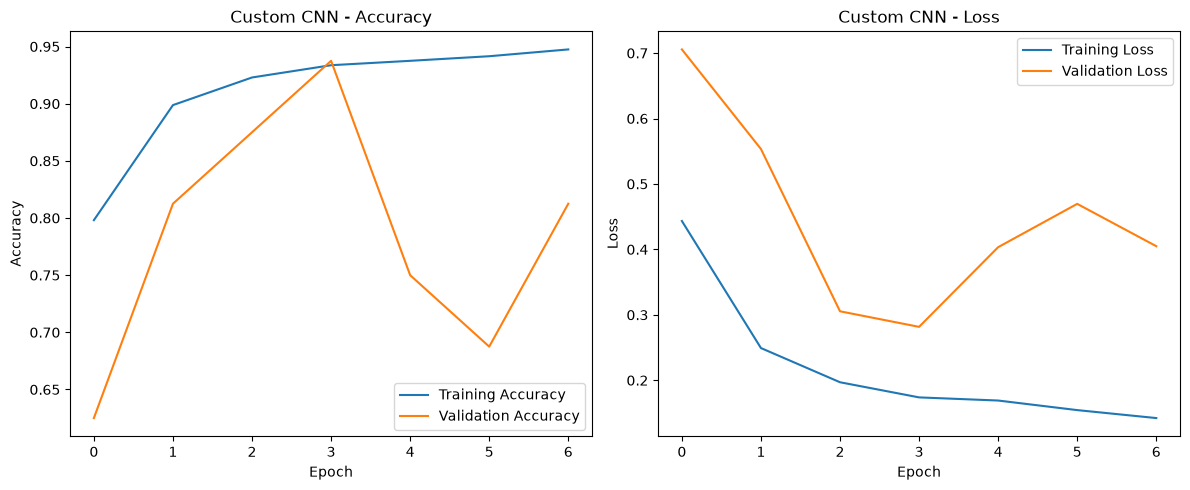

In [9]:
# Plot training and validation accuracy/loss

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Custom CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Custom CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
# Evaluate the trained CNN on the test set

test_results = model.evaluate(test_ds, verbose=1)

print("\nTest Results")
print("=" * 40)

for metric_name, value in zip(model.metrics_names, test_results):
    print(f"{metric_name}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 265ms/step - accuracy: 0.8894 - loss: 0.3016 - precision: 0.8759 - recall: 0.9590

Test Results
loss: 0.3016
compile_metrics: 0.8894


In [11]:
# Generate predictions for the test dataset

y_true = []
y_prob = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)

    y_prob.extend(probabilities.ravel())
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Total test samples:", len(y_true))
print("Predictions generated successfully.")

Total test samples: 624
Predictions generated successfully.


In [12]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

# F1-score
f1 = f1_score(y_true, y_pred)

# ROC-AUC
roc_auc = roc_auc_score(y_true, y_prob)

print(f"\nF1-Score: {f1:.4f}")
print(f"ROC-AUC:  {roc_auc:.4f}")

Confusion Matrix:
[[181  53]
 [ 16 374]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9188    0.7735    0.8399       234
   PNEUMONIA     0.8759    0.9590    0.9155       390

    accuracy                         0.8894       624
   macro avg     0.8973    0.8662    0.8777       624
weighted avg     0.8920    0.8894    0.8872       624


F1-Score: 0.9155
ROC-AUC:  0.9544


<Figure size 700x600 with 0 Axes>

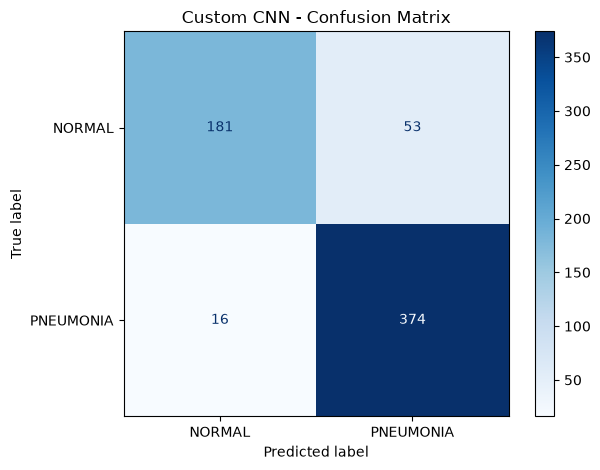

In [13]:
# Plot confusion matrix

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Custom CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

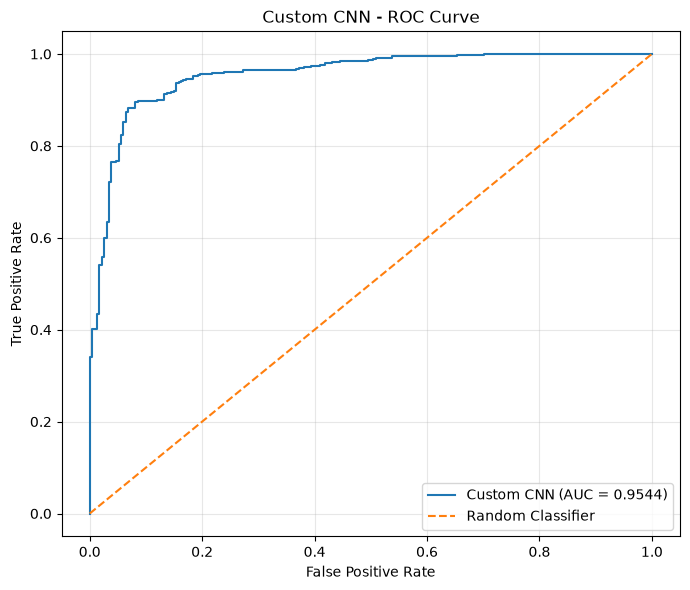

In [14]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Custom CNN (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Custom CNN - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 700x600 with 0 Axes>

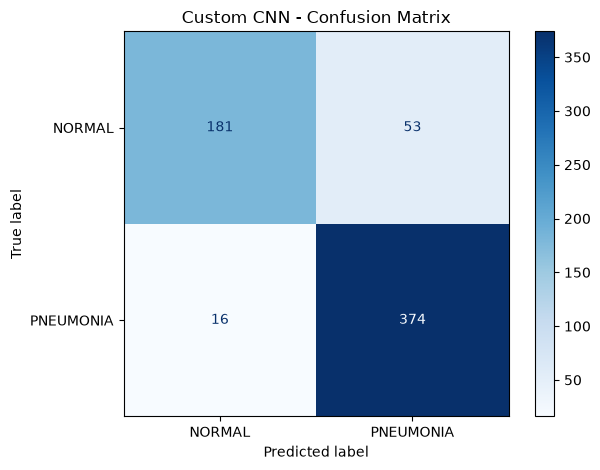

In [15]:
# Plot confusion matrix

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Custom CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

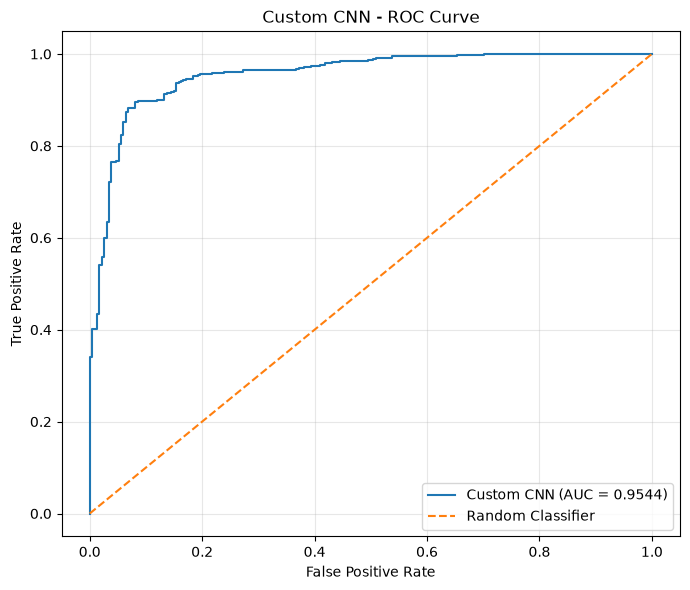

In [16]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Custom CNN (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Custom CNN - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Save Custom CNN evaluation results

custom_cnn_results = {
    "Model": "Custom CNN",
    "Test Accuracy": 0.8894,
    "Precision": 0.8759,
    "Recall": 0.9590,
    "F1-Score": 0.9155,
    "ROC-AUC": 0.9544,
    "Test Loss": 0.3016
}

results_df = pd.DataFrame([custom_cnn_results])

results_df.to_csv(
    "../results/custom_cnn_results.csv",
    index=False
)

print("✅ Custom CNN results saved!")
print(results_df)

NameError: name 'pd' is not defined

In [18]:
import pandas as pd

# Save Custom CNN evaluation results

custom_cnn_results = {
    "Model": "Custom CNN",
    "Test Accuracy": 0.8894,
    "Precision": 0.8759,
    "Recall": 0.9590,
    "F1-Score": 0.9155,
    "ROC-AUC": 0.9544,
    "Test Loss": 0.3016
}

results_df = pd.DataFrame([custom_cnn_results])

results_df.to_csv(
    "../results/custom_cnn_results.csv",
    index=False
)

print("✅ Custom CNN results saved!")
print(results_df)

✅ Custom CNN results saved!
        Model  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC  Test Loss
0  Custom CNN         0.8894     0.8759   0.959    0.9155   0.9544     0.3016
